# AIDA 2156 Project Exercise 05 – Weekly Workload Patterns

**Question:** How do weekly request arrivals, team completions, and outstanding requests change over the simulated period, and does the time window support a trend claim?

This notebook uses the original synthetic `requests.csv` from AIDA 1141 Exercise 02. One row represents one onboarding task. It counts arrivals and team completions in each week and the number of requests submitted but not yet team-completed at the end of each week.

The counts describe request volume and outstanding requests in generated data. They do not measure staff effort or team capacity.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

DATA_PATH = Path("../../../AIDA-1141/project-labs/02-synthetic-request-records/data/requests.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

ARRIVAL, COMPLETION = "submitted_at", "team_completed_at"
# Only truly empty cells become missing (NaN); the text "not_applicable" stays as a value
requests = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""], parse_dates=[ARRIVAL, COMPLETION])
assert all(pd.api.types.is_datetime64_any_dtype(requests[c]) for c in [ARRIVAL, COMPLETION]), \
    "Arrival or completion timestamps were not parsed as datetimes."
print(f"Loaded {len(requests):,} requests")

Loaded 2,064 requests


## A. Date checks and assumptions

- **Arrival** is `submitted_at`. **Completion** is `team_completed_at`, when the responsible team finishes the task. This matches AIDA 2156 Exercise 03 and the AIDA 1141 readiness deadline; the later coordinator confirmation is not counted.
- **Weeks** run Monday to Sunday and are labelled by their Monday date. All timestamps use one fixed local clock with no time zones or daylight saving, and the simulated working days are Monday to Friday with no holidays.
- **Window:** every week from the week of the first observed arrival (Wednesday 21 January 2026) to the week of the last team completion (Thursday 1 October 2026), including any weeks with no events.
- **Complete request follow-up:** the generator follows every included request through to team completion. Boundary weeks reflect the beginning and end of this finite simulated cohort, rather than missing follow-up. Days without events are counted as zero.

The checks confirm that both timestamp columns load as dates, IDs are complete and unique, every request has both timestamps, completion is never before arrival, and all timestamps fall on weekdays.

In [2]:
checks = pd.Series({
    "Request IDs are complete and unique": requests["request_id"].notna().all() and requests["request_id"].is_unique,
    "Every request has an arrival and a team-completion time": requests[[ARRIVAL, COMPLETION]].notna().all().all(),
    "Team completion is never before arrival": (requests[COMPLETION] >= requests[ARRIVAL]).all(),
    "Arrivals and completions fall on weekdays": all((requests[c].dt.dayofweek < 5).all() for c in [ARRIVAL, COMPLETION]),
}, name="passed")
assert checks.all(), "A date check failed."

date_range = pd.DataFrame({"first": requests[[ARRIVAL, COMPLETION]].min(), "last": requests[[ARRIVAL, COMPLETION]].max()})
date_range["first_weekday"] = date_range["first"].dt.day_name()
date_range["last_weekday"] = date_range["last"].dt.day_name()
display(checks.to_frame())
date_range[["first", "first_weekday", "last", "last_weekday"]]

,passed
Request IDs are complete and unique,True
Every request has an arrival and a team-completion time,True
Team completion is never before arrival,True
Arrivals and completions fall on weekdays,True


,first,first_weekday,last,last_weekday
submitted_at,2026-01-21 08:09:00,Wednesday,2026-09-21 11:08:00,Monday
team_completed_at,2026-01-22 12:03:00,Thursday,2026-10-01 09:17:00,Thursday


## B. Weekly table

For each week, the table counts:

- **arrivals:** requests submitted during the week;
- **team completions:** requests completed by the responsible team during the week;
- **submitted but not team-completed at week end:** requests submitted before the following Monday at 00:00 whose team completion occurs at or after that boundary. This includes requests waiting for information, waiting for assignment, or in progress, and excludes requests the team has finished that are awaiting coordinator confirmation.

The end-of-week count is calculated directly from the timestamps and then checked against the weekly flow: previous week's count + arrivals − team completions. Completions can exceed arrivals in a week when earlier requests are being finished.

In [3]:
def week_start(timestamps):
    """Monday of the Monday-Sunday week containing each timestamp."""
    return timestamps.dt.normalize() - pd.to_timedelta(timestamps.dt.dayofweek, unit="D")

# Every week from the week of the first arrival to the week of the last team completion, including zero-count weeks
weeks = pd.date_range(week_start(requests[ARRIVAL]).min(), week_start(requests[COMPLETION]).max(), freq="W-MON")
weekly = pd.DataFrame(index=pd.Index(weeks, name="week_starting"))
weekly["arrivals"] = week_start(requests[ARRIVAL]).value_counts().reindex(weeks, fill_value=0)
weekly["team_completions"] = week_start(requests[COMPLETION]).value_counts().reindex(weeks, fill_value=0)

# Outstanding immediately before the next Monday at 00:00, counted directly from the timestamps
week_end = weeks + pd.Timedelta(days=7)
weekly["outstanding_end_of_week"] = [int(((requests[ARRIVAL] < end) & (requests[COMPLETION] >= end)).sum())
                                     for end in week_end]

# Check: end-of-week outstanding = previous outstanding + arrivals - team completions
previous = weekly["outstanding_end_of_week"].shift(1, fill_value=0)
flow_checks = pd.Series({
    "Weekly arrivals sum to all requests": weekly["arrivals"].sum() == len(requests),
    "Weekly team completions sum to all requests": weekly["team_completions"].sum() == len(requests),
    "Outstanding = previous + arrivals - completions, every week":
        (weekly["outstanding_end_of_week"] == previous + weekly["arrivals"] - weekly["team_completions"]).all(),
    "Nothing outstanding after the last week": weekly["outstanding_end_of_week"].iloc[-1] == 0,
}, name="passed")
assert flow_checks.all(), "A weekly flow check failed."

weekly.to_csv(OUTPUT_DIR / "weekly_workload.csv")
display(flow_checks.to_frame())
print(f"{len(weekly)} weeks, from {weeks[0]:%d %b %Y} to the week starting {weeks[-1]:%d %b %Y}")
weekly

,passed
Weekly arrivals sum to all requests,True
Weekly team completions sum to all requests,True
"Outstanding = previous + arrivals - completions, every week",True
Nothing outstanding after the last week,True


37 weeks, from 19 Jan 2026 to the week starting 28 Sep 2026


,arrivals,team_completions,outstanding_end_of_week
week_starting,,,
2026-01-19,5,1,4
2026-01-26,42,12,34
2026-02-02,23,34,23
2026-02-09,56,33,46
2026-02-16,44,52,38
2026-02-23,48,46,40
2026-03-02,52,45,47
2026-03-09,49,48,48
2026-03-16,48,49,47


## C. Plot

The top panel shows weekly arrivals and team completions. The bottom panel, on the same time axis, shows requests submitted but not team-completed at week end. Points and bars are positioned at the Monday starting each week; the bottom panel reports the outstanding count immediately before the following Monday, rather than at the plotted date.

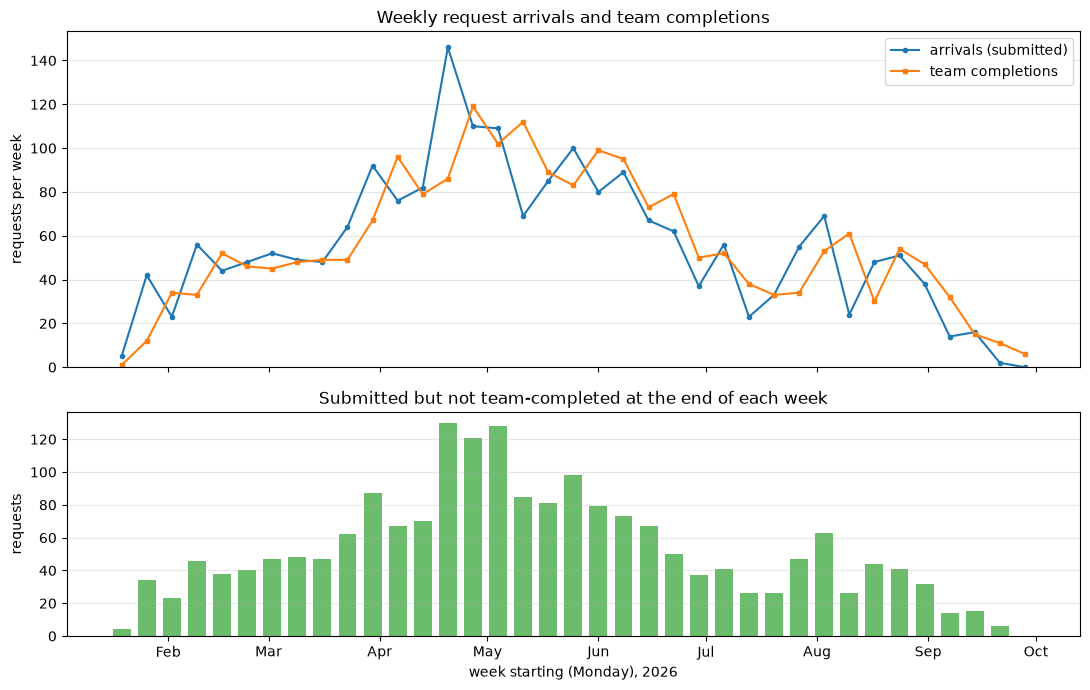

In [4]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
top.plot(weekly.index, weekly["arrivals"], marker="o", ms=3, label="arrivals (submitted)")
top.plot(weekly.index, weekly["team_completions"], marker="s", ms=3, label="team completions")
top.set_ylabel("requests per week")
top.set_title("Weekly request arrivals and team completions")
top.legend()
bottom.bar(weekly.index, weekly["outstanding_end_of_week"], width=5, color="C2", alpha=0.7)
bottom.set_ylabel("requests")
bottom.set_title("Submitted but not team-completed at the end of each week")
bottom.set_xlabel("week starting (Monday), 2026")
bottom.xaxis.set_major_locator(mdates.MonthLocator())
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in (top, bottom):
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "weekly_workload.png", dpi=120)
plt.show()

## D. Weekly summary

A short summary of the weekly table: the number of weeks, the median weekly arrivals, the busiest arrival week, how many weeks had more completions than arrivals, and the highest end-of-week outstanding count. Weeks are identified by their starting Monday, and the first week is reported if several share the highest value. The five busiest arrival weeks are listed below it.

In [5]:
busiest = weekly.nlargest(5, "arrivals")
# idxmax() returns the first week if several weeks share the highest value
summary = pd.Series({
    "weeks": len(weekly),
    "median weekly arrivals": f"{weekly['arrivals'].median():g}",
    "busiest arrival week": (f"week starting {weekly['arrivals'].idxmax():%d %b} "
                             f"({weekly['arrivals'].max()} arrivals)"),
    "weeks with completions above arrivals": int((weekly["team_completions"] > weekly["arrivals"]).sum()),
    "highest end-of-week outstanding": (f"week starting {weekly['outstanding_end_of_week'].idxmax():%d %b} "
                                        f"({weekly['outstanding_end_of_week'].max()} requests)"),
}, name="value")
display(summary.to_frame())
busiest

,value
weeks,37
median weekly arrivals,52
busiest arrival week,week starting 20 Apr (146 arrivals)
weeks with completions above arrivals,19
highest end-of-week outstanding,week starting 20 Apr (130 requests)


,arrivals,team_completions,outstanding_end_of_week
week_starting,,,
2026-04-20,146,86,130
2026-04-27,110,119,121
2026-05-04,109,102,128
2026-05-25,100,83,98
2026-03-30,92,67,87


## E. Interpretation and trend note

**Fluctuation.** Weekly request arrivals fluctuated within the simulated period. From February to mid-March, arrivals ranged from 23 to 56 a week. They rose from late March to a peak of 146 in the week starting 20 April, stayed between 62 and 110 a week from late April to late June, ranged from 23 to 69 in July and August, and fell to 16 or fewer from the week starting 7 September. Week-to-week changes were sometimes large, such as 69 arrivals in the week starting 3 August followed by 24.

**Outstanding requests.** Requests submitted but not team-completed reached 130 at the end of the week starting 20 April and stayed at 121–128 for the next two weeks. Team completions exceeded arrivals in 19 of the 37 weeks, as earlier requests were finished.

**Trend claim.** The 37-week window supports describing fluctuations within this simulation, but not establishing a persistent trend or recurring seasonality. It covers one partial year and one generated group of 500 new hires, so there is no second year to show whether the spring rise repeats. The pattern is consistent with the generator's settings, which place start dates between 23 February and 30 September, place seasonal starts between April and June, and submit requests a set range of working days before each start date, but weekly counts alone do not establish how much each setting contributes.

**What the counts do not show.** They describe request volume and outstanding requests, not staff effort, team capacity, or real HR workload. In a real dataset extracted at a fixed date, some requests may still be incomplete, especially recent arrivals. Here, every included request is followed through to team completion.